# 05 — Modèles de référence (baselines)

**Objectif** : établir les **performances à battre** avant toute modélisation avancée. Un modèle complexe n'a de valeur que s'il fait mieux que des approches simples ; sans référence, un score élevé ne veut rien dire.

**Références évaluées**
1. **Modèle naïf** : ne signale jamais de fraude (borne inférieure) ;
2. **Règle métier existante** : `isFlaggedFraud` ;
3. **Règle « compte vidé »** : `amount = oldbalanceOrig > 0`, issue de H3 ;
4. **Régression logistique** pondérée, sur les deux jeux de variables (`complet` et `transaction`).

**Protocole** : apprentissage sur le **train**, évaluation sur la **validation** (le test reste intact). Toutes les métriques sont calculées par `src/evaluate.py`.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

from src.config import TARGET, COST_FALSE_POSITIVE, MODELS_DIR
from src.split import load_split
from src.baselines import RegleIsFlagged, RegleCompteVide, make_logistic_regression
from src.evaluate import compare_models, plot_pr_curves, save_results, MODEL_COLORS
from src.viz import set_style, save_fig, COLOR_LEGIT, COLOR_FRAUD, TEXT_SECONDARY

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train, val = load_split("train"), load_split("val")
y_train, y_val = train[TARGET].to_numpy(), val[TARGET].to_numpy()
amounts_val = val["amount"].to_numpy()
print(f"Train : {len(train):,} transactions, {y_train.sum():,} fraudes")
print(f"Val   : {len(val):,} transactions, {y_val.sum():,} fraudes "
      f"(montant frauduleux total : {amounts_val[y_val == 1].sum() / 1e6:,.1f} M)")
print(f"Coût d'une fausse alerte (hypothèse) : {COST_FALSE_POSITIVE:,}")

Train : 1,917,584 transactions, 3,511 fraudes
Val   : 346,348 transactions, 498 fraudes (montant frauduleux total : 694.8 M)
Coût d'une fausse alerte (hypothèse) : 5,000


## 1. Rappel des métriques

| Métrique | Question à laquelle elle répond |
|---|---|
| **PR-AUC** (métrique principale) | Le modèle classe-t-il bien les fraudes en tête, indépendamment du seuil ? |
| **Précision** | Parmi les alertes, quelle part est réellement frauduleuse ? |
| **Rappel** | Quelle part des fraudes est détectée ? |
| **F2** | Synthèse privilégiant le rappel (une fraude ratée coûte plus qu'une fausse alerte) |
| **Montant détecté (%)** | Quelle part de l'argent fraudé est interceptée ? |
| **Coût total** | Montant des fraudes ratées + nombre de fausses alertes × coût d'une alerte |

## 2. Modèle naïf et règles

In [2]:
rule_flag = RegleIsFlagged().fit(train)
rule_vide = RegleCompteVide().fit(train)

scores = {
    "Naïf (jamais fraude)": np.zeros(len(val)),
    "Règle isFlaggedFraud": rule_flag.predict_proba(val)[:, 1],
    "Règle compte vidé": rule_vide.predict_proba(val)[:, 1],
}
print(f"Alertes isFlaggedFraud sur la validation : {int(scores['Règle isFlaggedFraud'].sum())}")
print(f"Alertes compte vidé sur la validation     : {int(scores['Règle compte vidé'].sum())}")

Alertes isFlaggedFraud sur la validation : 0
Alertes compte vidé sur la validation     : 494


## 3. Régression logistique

Choix de modélisation :
- **Standardisation** des variables (indispensable pour un modèle linéaire régularisé) ;
- **`class_weight="balanced"`** : chaque fraude pèse ~550 fois plus qu'une transaction légitime dans la fonction de perte. On compense ainsi le déséquilibre **sans rééchantillonner** (les stratégies de rééchantillonnage seront comparées en Phase 7) ;
- **Régularisation L2** (C = 1), qui limite l'instabilité due aux variables corrélées.

In [3]:
models = {}
for feature_set in ["complet", "transaction"]:
    start = time.perf_counter()
    model = make_logistic_regression(feature_set).fit(train, y_train)
    models[feature_set] = model
    name = f"Logistique ({feature_set})"
    scores[name] = model.predict_proba(val)[:, 1]
    print(f"{name:<26} entraînée en {time.perf_counter() - start:5.1f} s")

MODELS_DIR.mkdir(exist_ok=True)
_ = joblib.dump(models["complet"], MODELS_DIR / "baseline_logistique_complet.joblib")

Logistique (complet)       entraînée en   6.9 s


Logistique (transaction)   entraînée en   2.7 s


### Pourquoi la règle « compte vidé » rate-t-elle 4 fraudes ?

In [4]:
rule_pred = scores["Règle compte vidé"] == 1
missed = val[(y_val == 1) & ~rule_pred]
missed[["step", "type", "amount", "oldbalanceOrig", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]]

,step,type,amount,oldbalanceOrig,newbalanceOrig,oldbalanceDest,newbalanceDest
248,312,TRANSFER,"10,000,000.0000","16,580,427.8100","6,580,427.8100",0.0000,0.0000
283598,354,TRANSFER,"10,000,000.0000","19,299,230.1300","9,299,230.1300",0.0000,0.0000
339538,357,TRANSFER,"10,000,000.0000","10,653,151.5500","653,151.5500",0.0000,0.0000
345451,359,TRANSFER,"10,000,000.0000","12,056,779.2400","2,056,779.2400",0.0000,0.0000


Les 4 fraudes manquées sont des transferts d'**exactement 10 000 000** depuis des comptes contenant **plus** de 10 M : le simulateur plafonne chaque transaction frauduleuse à 10 M, le compte n'est donc pas vidé en une seule opération. Ce sont pourtant les fraudes **les plus coûteuses** : elles représentent à elles seules 40 M de pertes, soit 5,8 % du montant fraudé de la validation.

## 4. Comparaison au seuil par défaut (0,5)

In [5]:
results = compare_models(scores, y_val, amounts=amounts_val)
cols = ["pr_auc", "roc_auc", "precision", "rappel", "f2", "n_alertes", "fp", "fn",
        "montant_detecte_pct", "cout_total"]
display_df = results[cols].copy()
display_df["cout_total"] = display_df["cout_total"] / 1e6
display_df = display_df.rename(columns={"cout_total": "cout_total (M)"})
display_df

,pr_auc,roc_auc,precision,rappel,f2,n_alertes,fp,fn,montant_detecte_pct,cout_total (M)
Naïf (jamais fraude),0.0014,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,498.0000,0.0000,694.7816
Règle isFlaggedFraud,0.0014,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,498.0000,0.0000,694.7816
Règle compte vidé,0.9920,0.9960,1.0000,0.9920,0.9936,494.0000,0.0000,4.0000,94.2428,40.0000
Logistique (complet),1.0000,1.0000,0.8957,1.0000,0.9772,556.0000,58.0000,0.0000,100.0000,0.2900
Logistique (transaction),0.0500,0.8173,0.0048,0.6948,0.0235,"71,593.0000","71,247.0000",152.0000,84.8558,461.4538


In [6]:
path = save_results(results, "05_baselines_validation")
print(f"Résultats sauvegardés : {path.relative_to(ROOT)}")

Résultats sauvegardés : reports\results\05_baselines_validation.csv


## 5. Courbes précision-rappel

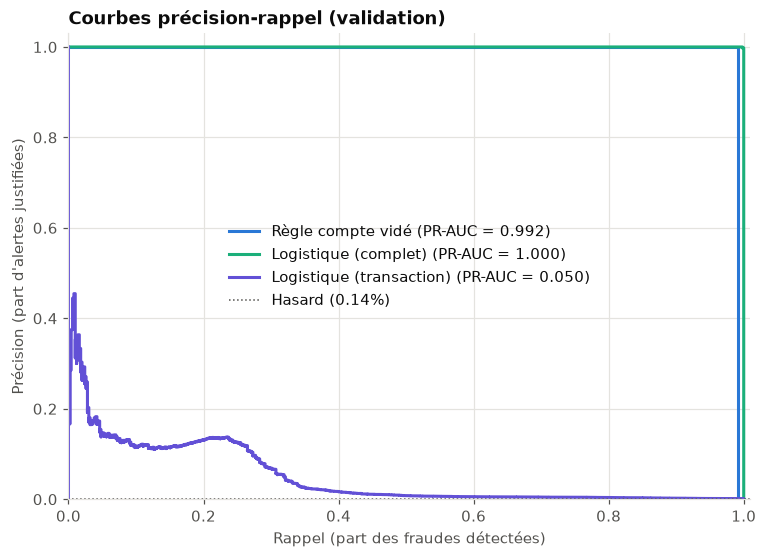

In [7]:
curves = {k: v for k, v in scores.items() if not k.startswith("Naïf") and k != "Règle isFlaggedFraud"}
fig, ax = plt.subplots(figsize=(8, 5.5))
plot_pr_curves(ax, curves, y_val, legend_loc="center")
ax.set_title("Courbes précision-rappel (validation)")
save_fig(fig, "05_courbes_pr_baselines")
plt.show()

## 6. Le seuil de 0,5 n'a rien de naturel

Avec `class_weight="balanced"`, les probabilités de la régression logistique sont **décalées vers le haut** : le modèle a appris comme si les classes étaient équilibrées. Le seuil de 0,5 produit donc beaucoup d'alertes. Le graphique montre comment précision et rappel évoluent avec le seuil.

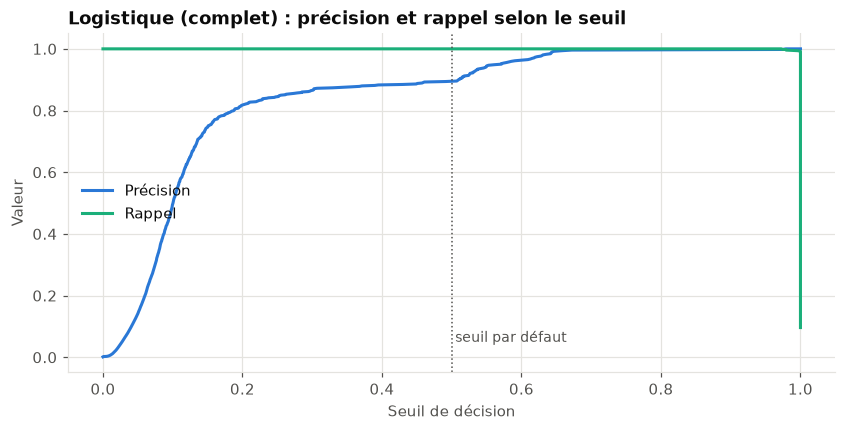

In [8]:
p, r, t = precision_recall_curve(y_val, scores["Logistique (complet)"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, p[:-1], color=MODEL_COLORS[0], label="Précision")
ax.plot(t, r[:-1], color=MODEL_COLORS[1], label="Rappel")
ax.axvline(0.5, color=TEXT_SECONDARY, linestyle=":", linewidth=1)
ax.text(0.505, 0.05, "seuil par défaut", color=TEXT_SECONDARY, fontsize=9)
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("Valeur")
ax.set_title("Logistique (complet) : précision et rappel selon le seuil")
ax.legend(loc="center left")
save_fig(fig, "05_seuil_logistique")
plt.show()

In [9]:
rows = []
for thr in [0.5, 0.9, 0.99, 0.999]:
    m = compare_models({"Logistique (complet)": scores["Logistique (complet)"]}, y_val,
                       thresholds={"Logistique (complet)": thr}, amounts=amounts_val).iloc[0]
    rows.append({"seuil": thr, "précision": m["precision"], "rappel": m["rappel"], "alertes": int(m["n_alertes"]),
                 "coût total (M)": m["cout_total"] / 1e6})
pd.DataFrame(rows).set_index("seuil")

,précision,rappel,alertes,coût total (M)
seuil,,,,
0.5000,0.8957,1.0000,556,0.2900
0.9000,0.9980,1.0000,499,0.0050
0.9900,1.0000,0.9940,495,30.0000
0.9990,1.0000,0.9920,494,40.0000


Le choix rigoureux du seuil (minimisation du coût métier sur la validation, analyse de sensibilité) fait l'objet de la Phase 8. Ici, il suffit de retenir que **comparer des modèles au seuil 0,5 est trompeur** : c'est pourquoi la **PR-AUC**, indépendante du seuil, est la métrique principale de comparaison.

## 7. Interprétation de la régression logistique

Les variables étant standardisées, les coefficients sont **comparables entre eux** : leur signe indique le sens de l'effet, leur valeur absolue son intensité (en log-odds par écart-type).

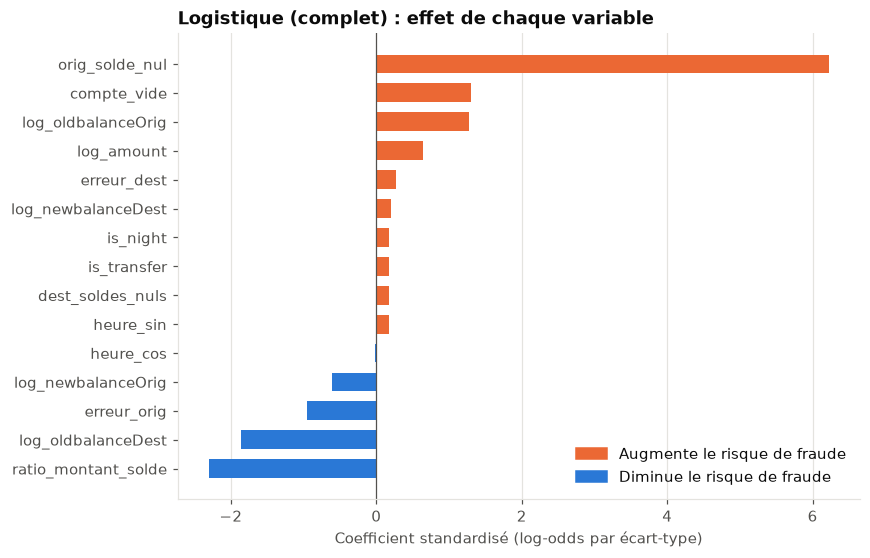

,coefficient
orig_solde_nul,6.2207
ratio_montant_solde,-2.3049
log_oldbalanceDest,-1.8567
compte_vide,1.3049
log_oldbalanceOrig,1.2764
erreur_orig,-0.9557
log_amount,0.6379
log_newbalanceOrig,-0.6067
erreur_dest,0.2762
log_newbalanceDest,0.2044


In [10]:
lr = models["complet"].named_steps["model"]
names = models["complet"].named_steps["preprocessing"].get_feature_names_out()
coefs = pd.Series(lr.coef_[0], index=names).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(coefs.index, coefs.values, color=[COLOR_FRAUD if v > 0 else COLOR_LEGIT for v in coefs.values], height=0.65)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_xlabel("Coefficient standardisé (log-odds par écart-type)")
ax.set_title("Logistique (complet) : effet de chaque variable")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (COLOR_FRAUD, COLOR_LEGIT)]
ax.legend(handles, ["Augmente le risque de fraude", "Diminue le risque de fraude"], loc="lower right")
save_fig(fig, "05_coefficients_logistique")
plt.show()
coefs.sort_values(key=abs, ascending=False).to_frame("coefficient")

**Interprétation et mise en garde**
- Le coefficient le plus fort est celui de `orig_solde_nul` (**+6,2**), alors qu'en EDA un solde émetteur nul était au contraire **associé aux transactions légitimes** (47,7 % des légitimes contre 0,8 % des fraudes). Ce n'est pas une erreur : dans un modèle multivarié, un coefficient mesure l'effet d'une variable **à autres variables constantes**. Or `orig_solde_nul`, `log_oldbalanceOrig` et `ratio_montant_solde` sont très corrélées (|ρ| > 0,86, notebook 04) : le modèle répartit l'information entre elles de façon peu intuitive.
- ➡️ Les coefficients d'une régression logistique **ne s'interprètent pas individuellement** quand les variables sont colinéaires. C'est une limite connue, qui justifie le recours à **SHAP** (Phase 9) pour expliquer les modèles de façon fiable.
- On retrouve néanmoins les signaux attendus : `compte_vide` et `log_oldbalanceOrig` augmentent le risque, `erreur_orig` et `ratio_montant_solde` le diminuent.

## 8. Conclusions

### Tableau des références (validation)

| Modèle | PR-AUC | Précision | Rappel | Montant détecté |
|---|---|---|---|---|
| Naïf / règle `isFlaggedFraud` | 0,001 | — | 0 % | 0 % |
| Règle « compte vidé » | 0,992 | 100 % | 99,2 % | 94,2 % |
| Logistique (`transaction`) | 0,050 | 0,5 % | 69,5 % | 84,9 % |
| **Logistique (`complet`)** | **1,000** | 89,6 % (seuil 0,5) | 100 % | 100 % |

### Enseignements
1. **La règle métier existante est inutile** : `isFlaggedFraud` ne lève **aucune** alerte sur la validation (elle n'en lève que 16 sur tout le jeu de données).
2. **Une règle d'une ligne fait presque tout** : « compte vidé » atteint 100 % de précision et 99,2 % de rappel. Elle ne rate que les fraudes plafonnées à 10 M, qui sont aussi les plus coûteuses.
3. **La régression logistique sur toutes les variables sépare parfaitement les classes** (PR-AUC = 1,000). Au seuil de 0,9, elle détecte les 498 fraudes avec une seule fausse alerte. Ce résultat confirme ce que l'EDA laissait prévoir : avec les variables de soldes, **le problème est trivial sur ces données simulées**, à cause des artefacts du simulateur.
4. **Sans variables de soldes, le problème devient difficile** : la logistique `transaction` n'atteint qu'une PR-AUC de 0,05 (36 fois mieux que le hasard, mais avec une précision de 0,5 %). C'est le **vrai défi de modélisation** du projet, et le cas le plus proche d'une situation réelle où les soldes ne trahissent pas la fraude.
5. **Le seuil de 0,5 est arbitraire** avec une pondération des classes : il doit être choisi selon le coût métier (Phase 8).

### Conséquences pour la Phase 7
- Sur le jeu `complet`, il n'y a presque plus rien à gagner en PR-AUC : l'enjeu sera de **vérifier la robustesse** (jeu de drift) et de **ne pas sur-interpréter** un score parfait.
- Sur le jeu `transaction`, la marge de progression est énorme : c'est là que les modèles non linéaires (Random Forest, XGBoost, LightGBM) et les stratégies de rééquilibrage seront réellement comparés.
- Objectifs à battre sur la validation : **PR-AUC 0,992** (règle compte vidé) pour le jeu complet, **PR-AUC 0,050** (logistique) pour le jeu transaction.